In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import pandas as pd

path = "/content/drive/MyDrive/givemesomecredit/"

train = pd.read_csv(path + "cs-training.csv")
test = pd.read_csv(path + "cs-test.csv")

print(train.shape)
print(test.shape)

train.head(10)

(150000, 12)
(101503, 12)


,Unnamed: 0,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0
5,6,0,0.213179,74,0,0.375607,3500.0,3,0,1,0,1.0
6,7,0,0.305682,57,0,5710.000000,NaN,8,0,3,0,0.0
7,8,0,0.754464,39,0,0.209940,3500.0,8,0,0,0,0.0
8,9,0,0.116951,27,0,46.000000,NaN,2,0,0,0,NaN
9,10,0,0.189169,57,0,0.606291,23684.0,9,0,4,0,2.0


In [3]:
test.head(10)

,Unnamed: 0,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,NaN,0.885519,43,0,0.177513,5700.0,4,0,0,0,0.0
1,2,NaN,0.463295,57,0,0.527237,9141.0,15,0,4,0,2.0
2,3,NaN,0.043275,59,0,0.687648,5083.0,12,0,1,0,2.0
3,4,NaN,0.280308,38,1,0.925961,3200.0,7,0,2,0,0.0
4,5,NaN,1.000000,27,0,0.019917,3865.0,4,0,0,0,1.0
5,6,NaN,0.509791,63,0,0.342429,4140.0,4,0,0,0,1.0
6,7,NaN,0.587778,50,0,1048.000000,0.0,5,0,0,0,3.0
7,8,NaN,0.046149,79,1,0.369170,3301.0,8,0,1,0,1.0
8,9,NaN,0.013527,68,0,2024.000000,NaN,4,0,1,0,0.0
9,10,NaN,1.000000,23,98,0.000000,0.0,0,98,0,98,0.0


some informations about our model

In [4]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 12 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   Unnamed: 0                            150000 non-null  int64  
 1   SeriousDlqin2yrs                      150000 non-null  int64  
 2   RevolvingUtilizationOfUnsecuredLines  150000 non-null  float64
 3   age                                   150000 non-null  int64  
 4   NumberOfTime30-59DaysPastDueNotWorse  150000 non-null  int64  
 5   DebtRatio                             150000 non-null  float64
 6   MonthlyIncome                         120269 non-null  float64
 7   NumberOfOpenCreditLinesAndLoans       150000 non-null  int64  
 8   NumberOfTimes90DaysLate               150000 non-null  int64  
 9   NumberRealEstateLoansOrLines          150000 non-null  int64  
 10  NumberOfTime60-89DaysPastDueNotWorse  150000 non-null  int64  
 11  

In [5]:
test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101503 entries, 0 to 101502
Data columns (total 12 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   Unnamed: 0                            101503 non-null  int64  
 1   SeriousDlqin2yrs                      0 non-null       float64
 2   RevolvingUtilizationOfUnsecuredLines  101503 non-null  float64
 3   age                                   101503 non-null  int64  
 4   NumberOfTime30-59DaysPastDueNotWorse  101503 non-null  int64  
 5   DebtRatio                             101503 non-null  float64
 6   MonthlyIncome                         81400 non-null   float64
 7   NumberOfOpenCreditLinesAndLoans       101503 non-null  int64  
 8   NumberOfTimes90DaysLate               101503 non-null  int64  
 9   NumberRealEstateLoansOrLines          101503 non-null  int64  
 10  NumberOfTime60-89DaysPastDueNotWorse  101503 non-null  int64  
 11  

let's fill the missing values bro

In [6]:
for df in [train, test]:
  df['NumberOfDependents'] = df['NumberOfDependents'].fillna(df['NumberOfDependents'].median())

### To fill MonthlyIncome let's get some informations first

In [7]:
train['MonthlyIncome'].describe().apply(lambda x: format(x, '.2f'))

,MonthlyIncome
count,120269.00
mean,6670.22
std,14384.67
min,0.00
25%,3400.00
50%,5400.00
75%,8249.00
max,3008750.00


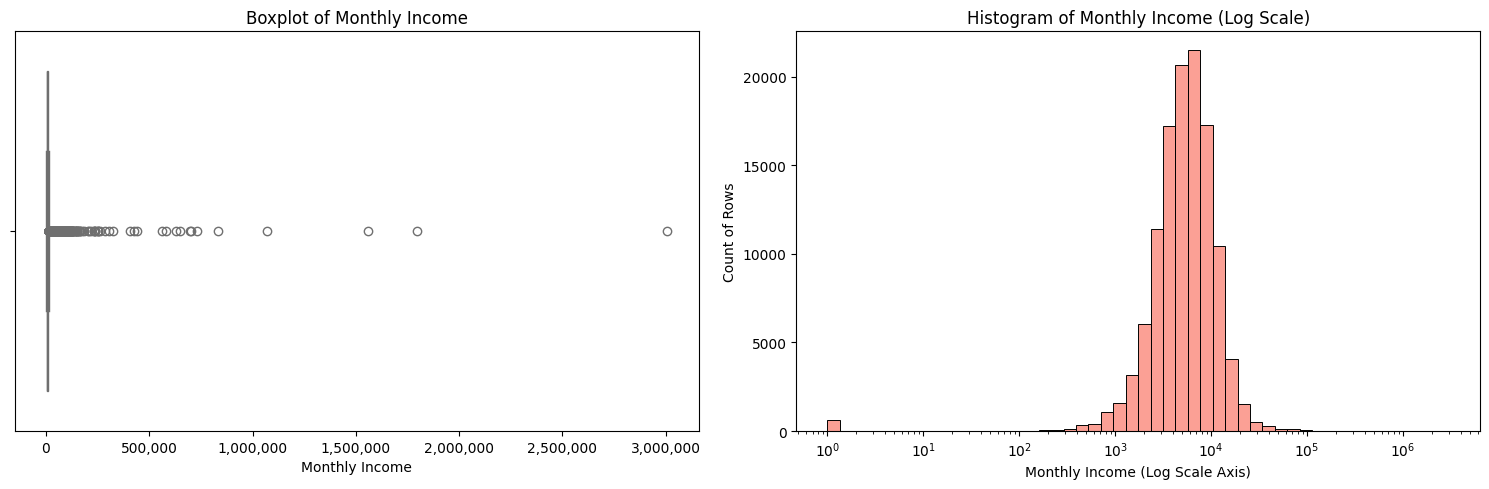

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set up a side-by-side plot area
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Boxplot - Great for explicitly spotting extreme outliers
sns.boxplot(x=train['MonthlyIncome'], ax=axes[0], color='skyblue')
axes[0].set_title('Boxplot of Monthly Income')
axes[0].set_xlabel('Monthly Income')
# Format numbers on x-axis with commas for readability
axes[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: f"{int(x):,}"))

# 2. Histogram with Log Scale - Crucial when data ranges from 0 to 3+ million
# Using log_scale=True allows you to see both the main distribution and the distant outliers
sns.histplot(train['MonthlyIncome'], bins=50, ax=axes[1], color='salmon', log_scale=(True, False))
axes[1].set_title('Histogram of Monthly Income (Log Scale)')
axes[1].set_xlabel('Monthly Income (Log Scale Axis)')
axes[1].set_ylabel('Count of Rows')

plt.tight_layout()
plt.show()

we mark those who have income missing , so that we know theme

In [9]:
for df in [train, test]:
  df['IncomeMissing'] = df['MonthlyIncome'].isna().astype(int)

  df['MonthlyIncome'] = df['MonthlyIncome'].fillna(
      df['MonthlyIncome'].median()
)



In [10]:
train.groupby('SeriousDlqin2yrs')['MonthlyIncome'].median()

,MonthlyIncome
SeriousDlqin2yrs,
0,5400.0
1,5240.0


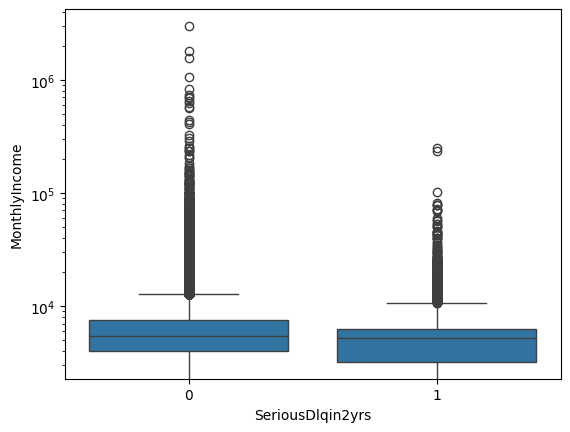

In [11]:
import seaborn as sns

sns.boxplot(
    x='SeriousDlqin2yrs',
    y='MonthlyIncome',
    data=train
)
plt.yscale('log')
plt.show()

ok we fill the missing values

In [12]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 13 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   Unnamed: 0                            150000 non-null  int64  
 1   SeriousDlqin2yrs                      150000 non-null  int64  
 2   RevolvingUtilizationOfUnsecuredLines  150000 non-null  float64
 3   age                                   150000 non-null  int64  
 4   NumberOfTime30-59DaysPastDueNotWorse  150000 non-null  int64  
 5   DebtRatio                             150000 non-null  float64
 6   MonthlyIncome                         150000 non-null  float64
 7   NumberOfOpenCreditLinesAndLoans       150000 non-null  int64  
 8   NumberOfTimes90DaysLate               150000 non-null  int64  
 9   NumberRealEstateLoansOrLines          150000 non-null  int64  
 10  NumberOfTime60-89DaysPastDueNotWorse  150000 non-null  int64  
 11  

In [13]:
test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101503 entries, 0 to 101502
Data columns (total 13 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   Unnamed: 0                            101503 non-null  int64  
 1   SeriousDlqin2yrs                      0 non-null       float64
 2   RevolvingUtilizationOfUnsecuredLines  101503 non-null  float64
 3   age                                   101503 non-null  int64  
 4   NumberOfTime30-59DaysPastDueNotWorse  101503 non-null  int64  
 5   DebtRatio                             101503 non-null  float64
 6   MonthlyIncome                         101503 non-null  float64
 7   NumberOfOpenCreditLinesAndLoans       101503 non-null  int64  
 8   NumberOfTimes90DaysLate               101503 non-null  int64  
 9   NumberRealEstateLoansOrLines          101503 non-null  int64  
 10  NumberOfTime60-89DaysPastDueNotWorse  101503 non-null  int64  
 11  

## EDA

so before starting , i want to sort values of income to see if i can actually clean this data

In [14]:
train.sort_values(
    by='MonthlyIncome',
    ascending=False
).head(20)

,Unnamed: 0,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,IncomeMissing
73763,73764,0,0.007328,52,0,0.001470,3008750.0,10,0,1,0,3.0,0
137140,137141,0,0.000000,68,0,0.002776,1794060.0,15,0,1,0,0.0,0
111365,111366,0,0.163856,44,0,0.004013,1560100.0,12,0,4,0,2.0,0
50640,50641,0,0.469025,44,1,0.004537,1072500.0,9,0,2,0,1.0,0
122543,122544,0,0.041599,55,0,0.000147,835040.0,8,0,0,0,0.0,0
123291,123292,0,0.226333,67,1,0.005570,730483.0,23,0,1,0,0.0,0
93564,93565,0,0.071628,50,0,0.008268,702500.0,12,0,4,0,2.0,0
96549,96550,0,0.064155,52,0,0.003698,699530.0,11,0,2,0,1.0,0
119136,119137,0,0.151329,49,0,0.001313,649587.0,8,0,0,1,3.0,0
37078,37079,0,0.000000,83,0,0.000000,629000.0,3,0,0,0,0.0,0


In [15]:
# Isolate high-income defaulters
high_income_defaulters = train[
    (train['SeriousDlqin2yrs'] == 1) &
    (train['MonthlyIncome'] > 50000)
]

high_income_defaulters[['MonthlyIncome', 'DebtRatio', 'RevolvingUtilizationOfUnsecuredLines',
                                'NumberOfTimes90DaysLate']].head(17)

,MonthlyIncome,DebtRatio,RevolvingUtilizationOfUnsecuredLines,NumberOfTimes90DaysLate
6658,81000.0,0.005642,0.804867,0
9477,78500.0,0.021669,0.136994,0
18922,78000.0,0.078012,1.000000,1
34770,250000.0,0.022712,0.375783,0
35354,70575.0,0.008516,0.168316,1
48490,69520.0,0.012356,1.623070,1
65728,55966.0,0.719174,0.036942,0
67678,234600.0,0.050533,0.000000,1
87219,53000.0,0.023151,0.025195,3
102586,53594.0,0.035376,0.284936,0


In [16]:
# Créer une colonne booléenne (1 si revenu = 0, sinon 0)
for df in [train, test]:
  df['IsZeroIncome'] = (df['MonthlyIncome'] == 0).astype(int)

l'age de 0 n'est pas possible

In [17]:
train = train[train['age'] >= 18]

In [18]:
train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 149999 entries, 0 to 149999
Data columns (total 14 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   Unnamed: 0                            149999 non-null  int64  
 1   SeriousDlqin2yrs                      149999 non-null  int64  
 2   RevolvingUtilizationOfUnsecuredLines  149999 non-null  float64
 3   age                                   149999 non-null  int64  
 4   NumberOfTime30-59DaysPastDueNotWorse  149999 non-null  int64  
 5   DebtRatio                             149999 non-null  float64
 6   MonthlyIncome                         149999 non-null  float64
 7   NumberOfOpenCreditLinesAndLoans       149999 non-null  int64  
 8   NumberOfTimes90DaysLate               149999 non-null  int64  
 9   NumberRealEstateLoansOrLines          149999 non-null  int64  
 10  NumberOfTime60-89DaysPastDueNotWorse  149999 non-null  int64  
 11  Numbe

entrainement du model

In [19]:
train.loc[[9477, 35354, 67678]]

,Unnamed: 0,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,IncomeMissing,IsZeroIncome
9477,9478,1,0.136994,35,0,0.021669,78500.0,4,0,1,0,2.0,0,0
35354,35355,1,0.168316,54,0,0.008516,70575.0,4,1,0,1,1.0,0,0
67678,67679,1,0.000000,53,4,0.050533,234600.0,17,1,6,1,0.0,0,0


In [20]:
import pandas as pd
import numpy as np
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, classification_report

# ─── Features ───────────────────────────────────────────
features = [
    'RevolvingUtilizationOfUnsecuredLines',
    'age',
    'NumberOfTime30-59DaysPastDueNotWorse',
    'DebtRatio',
    'MonthlyIncome',
    'IsZeroIncome',        # flag qu'on a créé
    'NumberOfOpenCreditLinesAndLoans',
    'NumberOfTimes90DaysLate',
    'NumberRealEstateLoansOrLines',
    'NumberOfTime60-89DaysPastDueNotWorse',
    'NumberOfDependents'
]

X = train[features]
y = train['SeriousDlqin2yrs']

# ─── Split ───────────────────────────────────────────────
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# ─── Modèle ──────────────────────────────────────────────
model = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=(y == 0).sum() / (y == 1).sum(),  # gère le déséquilibre des classes
    eval_metric='auc',
    random_state=42
)

model.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    verbose=50
)

# ─── Évaluation ──────────────────────────────────────────
val_preds = model.predict_proba(X_val)[:, 1]
auc = roc_auc_score(y_val, val_preds)
print(f"\nValidation AUC: {auc:.4f}")
print(classification_report(y_val, model.predict(X_val)))

[0]	validation_0-auc:0.82029
[50]	validation_0-auc:0.86698
[100]	validation_0-auc:0.86884
[150]	validation_0-auc:0.86951
[200]	validation_0-auc:0.86936
[250]	validation_0-auc:0.86857
[299]	validation_0-auc:0.86788

Validation AUC: 0.8679
              precision    recall  f1-score   support

           0       0.98      0.81      0.89     27995
           1       0.22      0.77      0.35      2005

    accuracy                           0.81     30000
   macro avg       0.60      0.79      0.62     30000
weighted avg       0.93      0.81      0.85     30000



In [21]:
# ─── Même preprocessing sur le test ─────────────────────
test['MonthlyIncome_missing'] = test['MonthlyIncome'].isnull().astype(int)
test['MonthlyIncome'] = test['MonthlyIncome'].fillna(train['MonthlyIncome'].median())
test['NumberOfDependents'] = test['NumberOfDependents'].fillna(train['NumberOfDependents'].median())

# ─── Prédiction ──────────────────────────────────────────
test_preds = model.predict_proba(test[features])[:, 1]

# ─── Fichier de submission ───────────────────────────────
submission = pd.DataFrame({
    'Id': test['Unnamed: 0'],          # adapte si la colonne ID s'appelle autrement
    'Probability': test_preds
})

submission.to_csv('submission.csv', index=False)
print(submission.head())
print(f"\nSubmission shape: {submission.shape}")

   Id  Probability
0   1     0.477484
1   2     0.439754
2   3     0.146673
3   4     0.522415
4   5     0.581549

Submission shape: (101503, 2)


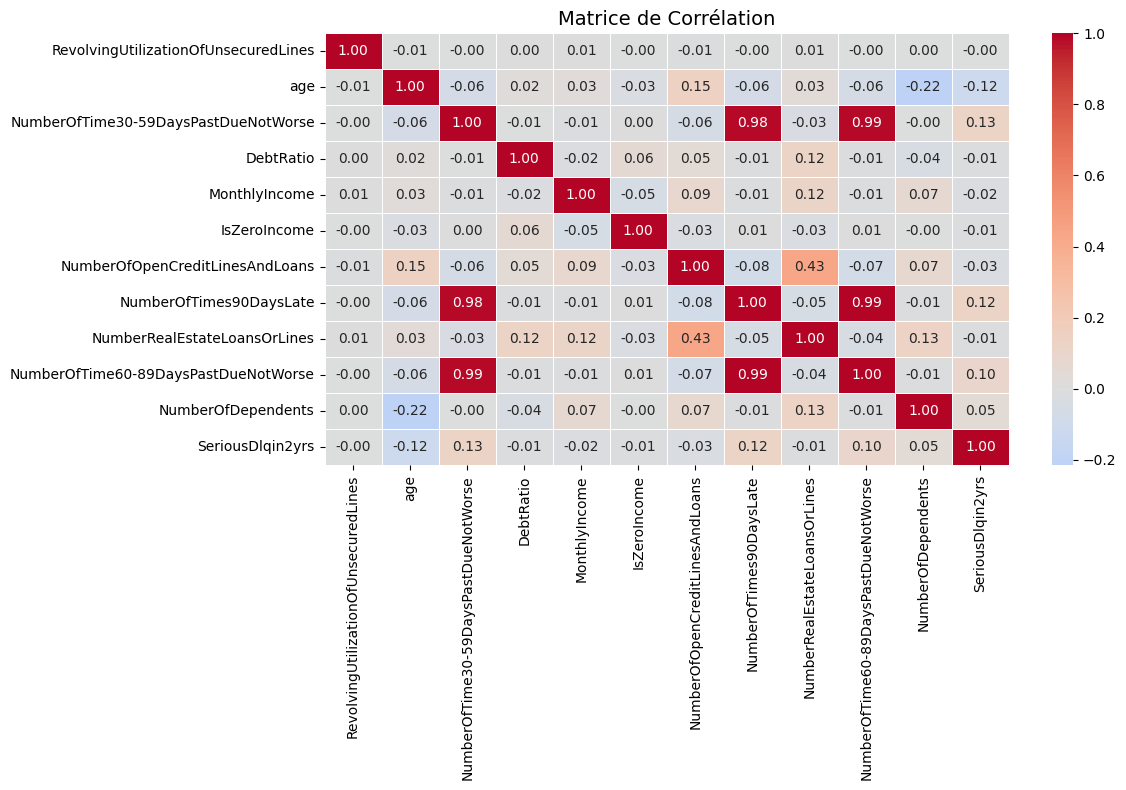

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 8))

cols = features + ['SeriousDlqin2yrs']   # ← target ajoutée
corr_matrix = train[cols].corr()

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    linewidths=0.5
)

plt.title('Matrice de Corrélation', fontsize=14)
plt.tight_layout()
plt.show()